# **<u>Data Analysis - Top Animation Shows</u>**

#### Andre Lira, Oct 23 2026

The dataset I used here was called "[22k Animated Movies and TV Shows](https://www.kaggle.com/datasets/kabhishm/20k-animated-movies-and-tv-shows)" and includes the following info:



- name

- rating
- certificate
- runtime
- description
- year of release
- genre
- number of votes.



My logic here was that I wanted to find the most universally loved shows so that our show, Topsy Turvy, could interpret this data to figure out which animation styles resonate most with people. The caveat here is that a show being highly rated doesn't necessarily mean that people only like it for its animation style (other factors like storyline, characters/dialogue, cultural moment etc impact this), but it could be a good indicator - if people hated the way the show looked, no amount of story would save the rating.

In [393]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [394]:
# after several unsuccessful attempts of replacing NaNs with integers with code, i just went ahead 
# and manually replaced all empty cells with zeros and saved them as a new csv
# if there's time, i may come back and redo this with the original original dataset and try again to replace these in code, 
# but I needed to move on and actually do some data analysis

path = 'AnimationData/tv_movie_animation 2_voteratingintegers.csv'
animation_df = pd.read_csv(path)

In [395]:
animation_df.columns

Index(['title', 'desc', 'year', 'genre', 'certificate', 'runtime', 'rating',
       'votes'],
      dtype='str')

In [396]:
# quick check to make sure that the votes column was showing up correctly and that instead of NaN it displayed 0
animation_df['votes']

0              0
1              0
2        141,620
3          3,370
4          5,035
          ...   
22365         10
22366         27
22367          0
22368          0
22369          0
Name: votes, Length: 22370, dtype: str

In [397]:
# quick check to see how all the columns would be displayed - looks like the database as initially sorted by title alphabetically
display(animation_df)

,title,desc,year,genre,certificate,runtime,rating,votes
0,4:19,4:19 was opened by Proprietor who is an evolve...,2022‚Äì,Animation,NaN,NaN,0.0,0
1,8,Add a Plot,2014,"Animation, Drama, Family",NaN,NaN,0.0,0
2,9,A rag doll that awakens in a postapocalyptic f...,I 2009,"Animation, Action, Adventure",PG-13,79 min,7.0,"141,620"
3,$9.99,A stop-motion animated story about people livi...,2008,"Animation, Drama, Fantasy",R,78 min,6.7,"3,370"
4,86,The Republic of San Magnolia is at war with it...,2021‚Äì2022,"Animation, Action, Drama",NaN,24 min,8.2,"5,035"
...,...,...,...,...,...,...,...,...
22365,Zverinice iz rezije,Add a Plot,1976‚Äì,Animation,NaN,19 min,8.4,10
22366,Zverinye voiny,The First and Only Animated Lampoon on Footbal...,2000,Animation,NaN,74 min,6.4,27
22367,Zvezdica Zaspanka,Add a Plot,1965,Animation,NaN,68 min,0.0,0
22368,Zwerg nase,Add a Plot,1955,Animation,NaN,NaN,0.0,0


In [398]:
# i want to see all of the most voted shows, so i tried at first to sort it by the number of votes...
animation_sortedvotes_df = animation_df.sort_values(by='votes',ascending=False) 
animation_sortedvotes_df

,title,desc,year,genre,certificate,runtime,rating,votes
5625,Fairfax,Animated series centering on four middle schoo...,2021‚Äì,"Animation, Adventure, Comedy",NaN,30 min,5.3,999
20189,Todd McFarlane's Spawn 2,Spawn - having become plagued by nightmares - ...,1998,"Animation, Action, Adventure",PG-13,146 min,8.3,998
1390,Avengers,The adventures of the Marvel Comics Universe's...,1999‚Äì2000,"Animation, Action, Adventure",NaN,30 min,5.3,998
2325,Bocchi the Rock!,"A shy, awkward, and lonely high school student...",2022‚Äì,"Animation, Comedy, Music",NaN,NaN,8.5,997
20407,Toy Story,A cowboy doll is profoundly threatened and jea...,1995,"Animation, Adventure, Comedy",U,81 min,8.3,"996,318"
...,...,...,...,...,...,...,...,...
10882,Los Creadores,Add a Plot,2015‚Äì,"Animation, Family",NaN,NaN,0.0,0
10886,Los Glubis,Add a Plot,2012‚Äì2013,Animation,NaN,NaN,0.0,0
10888,Los misterios de Jack el detective,Jack is the detective of the city of Madrid an...,2016‚Äì,"Animation, Crime, Mystery",NaN,NaN,0.0,0
10891,Los piratas y la calavera de plata,Join captain John Bonnet and his peculiar crew...,2022,"Animation, Adventure, Comedy",NaN,77 min,0.0,0


In [399]:
# ...but this isn't working like im expecting. it's sorting by the first few digits of the string instead of the whole one, so "999" appears to be bigger than "996,318"
#to fix this, we need to convert these values to integers instead of a string using pandas' "to numeric" function
animation_sortedvotes_df['votes'] = pd.to_numeric(animation_sortedvotes_df['votes'], errors='coerce')

animation_sortedvotes_df['votes'].dtypes

dtype('float64')

In [400]:
#i can see that the "to_numeric" function changed these to floats instead, so i need to convert it to an integer 
animation_sortedvotes_df['votes'] = animation_sortedvotes_df['votes'].astype(int)
animation_sortedvotes_df['votes'].dtypes

IntCastingNaNError: Cannot convert non-finite values (NA or inf) to integer.Replace or remove non-finite values or cast to an integer typethat supports these values (e.g. 'Int64')

In [401]:
#okay, so that didn't work. according to this function, there are 2668 cells that aren't a number.
animation_sortedvotes_df['votes'].isna().sum()

np.int64(2668)

In [402]:
# let's try this again, maybe the commas are an issue

animation_sortedvotes_df['votes'] = pd.to_numeric(
    animation_sortedvotes_df['votes'].astype(str).str.replace(',', ''),
    errors='coerce'
)
animation_sortedvotes_df['votes']

5625     999.0
20189    998.0
1390     998.0
2325     997.0
20407      NaN
         ...  
10882      0.0
10886      0.0
10888      0.0
10891      0.0
22369      0.0
Name: votes, Length: 22370, dtype: float64

In [403]:
# another weird bug here...
# when i go back to the previous sorted table, i can see that this "20407 NaN" refers to the entry for Toy Story which had a comma in the votes column, so something clearly went wrong here
# lets try this again but now do the comma removal BEFORE anything else
animation_votesnocomma_df = pd.to_numeric(
    animation_df['votes'].astype(str).str.replace(',', ''),
    errors='coerce'
)
animation_votesnocomma_df

0             0
1             0
2        141620
3          3370
4          5035
          ...  
22365        10
22366        27
22367         0
22368         0
22369         0
Name: votes, Length: 22370, dtype: int64

In [404]:
#okay, so that's better! but now we have an issue where the new animation_votesnocomma_df only displays the votes column instead of the whole database
animation_votesnocomma_df = animation_df # remake the votesnocommatable to point to the original animation_df before doing the to-numeric function
animation_votesnocomma_df['votes'] = pd.to_numeric(
    animation_df['votes'].astype(str).str.replace(',', ''),
    errors='coerce'
)
animation_votesnocomma_df

,title,desc,year,genre,certificate,runtime,rating,votes
0,4:19,4:19 was opened by Proprietor who is an evolve...,2022‚Äì,Animation,NaN,NaN,0.0,0
1,8,Add a Plot,2014,"Animation, Drama, Family",NaN,NaN,0.0,0
2,9,A rag doll that awakens in a postapocalyptic f...,I 2009,"Animation, Action, Adventure",PG-13,79 min,7.0,141620
3,$9.99,A stop-motion animated story about people livi...,2008,"Animation, Drama, Fantasy",R,78 min,6.7,3370
4,86,The Republic of San Magnolia is at war with it...,2021‚Äì2022,"Animation, Action, Drama",NaN,24 min,8.2,5035
...,...,...,...,...,...,...,...,...
22365,Zverinice iz rezije,Add a Plot,1976‚Äì,Animation,NaN,19 min,8.4,10
22366,Zverinye voiny,The First and Only Animated Lampoon on Footbal...,2000,Animation,NaN,74 min,6.4,27
22367,Zvezdica Zaspanka,Add a Plot,1965,Animation,NaN,68 min,0.0,0
22368,Zwerg nase,Add a Plot,1955,Animation,NaN,NaN,0.0,0


In [405]:
# to make this a little easier to read, let's remove the columns for description,year,genre,certificate,and runtime
animation_targetcols_df = animation_votesnocomma_df[['title', 'rating', 'votes']]
animation_targetcols_df

,title,rating,votes
0,4:19,0.0,0
1,8,0.0,0
2,9,7.0,141620
3,$9.99,6.7,3370
4,86,8.2,5035
...,...,...,...
22365,Zverinice iz rezije,8.4,10
22366,Zverinye voiny,6.4,27
22367,Zvezdica Zaspanka,0.0,0
22368,Zwerg nase,0.0,0


In [406]:
#now let's sort this by number of votes
animation_byvotes_df = animation_targetcols_df.sort_values(by='votes', ascending=False)
animation_byvotes_df

,title,rating,votes
21385,WALL¬∑E,8.4,1118407
19002,The Lion King,8.5,1060542
21015,Up,8.3,1046666
5852,Finding Nemo,8.2,1046425
20407,Toy Story,8.3,996318
...,...,...,...
10882,Los Creadores,0.0,0
10886,Los Glubis,0.0,0
10888,Los misterios de Jack el detective,0.0,0
10891,Los piratas y la calavera de plata,0.0,0


In [407]:
# i only want to include shows that had 10,000 votes or more
high_votes_df = animation_byvotes_df[animation_byvotes_df['votes'] >= 10000]
high_votes_df

,title,rating,votes
21385,WALL¬∑E,8.4,1118407
19002,The Lion King,8.5,1060542
21015,Up,8.3,1046666
5852,Finding Nemo,8.2,1046425
20407,Toy Story,8.3,996318
...,...,...,...
1295,Ast√©rix: Le secret de la potion magique,6.7,10094
3459,Clarence,6.8,10094
21545,"What's New, Scooby-Doo?",7.2,10057
9579,Kirikou et la sorci√®re,7.5,10026


In [408]:
# I wanted to find out a better way of really ranking these shows that took into account both the votes AND ranking, with my logic being:
# if you had a show with an 8.5 rating but 100k votes, is that inherently better than a 9.5 rating with 10,000 votes?

# I asked claude what stastical method I would use to work this out and they suggested a Bayesian Weighted Rating (also the same formula IMDb uses for its top 250 list
# It pulls every show’s rating toward the overall average, and the fewer votes a show has, the harder it gets pulled. 
# A show with 100,000 votes keeps almost all of its own rating; a show with 10,000 votes gets nudged more toward the middle.

# Claude provided the following formula for this: weighted rating = (v / (v + m)) * R  +  (m / (v + m)) * C
# R: the show’s average rating
# v: the show’s number of votes
# C: the mean rating across all shows in your dataset
# m: a “confidence threshold,” the number of votes you consider enough to trust a rating

high_votes_1_df = high_votes_df

C = high_votes_1_df['rating'].mean()
m = high_votes_1_df['votes'].quantile(0.50)  # median vote count

def weighted_rating(row):
    v = row['votes']
    R = row['rating']
    return (v / (v + m)) * R + (m / (v + m)) * C

high_votes_1_df['weighted_rating'] = high_votes_1_df.apply(weighted_rating, axis=1)

best_shows_bayesian_df = high_votes_1_df.sort_values(by='weighted_rating', ascending=False)
best_shows_bayesian_df[['title', 'rating', 'votes', 'weighted_rating']].head(50) # head(50) = output the top 50 shows

,title,rating,votes,weighted_rating
1385,Avatar: The Last Airbender,9.3,317686,9.109073
15160,Rick and Morty,9.1,527839,8.992296
16283,Shingeki no Kyojin,9.0,375741,8.860156
4165,Death Note: Desu n√¥to,9.0,327085,8.841238
7299,Hagane no renkinjutsushi,9.1,170030,8.802092
1133,Arcane: League of Legends,9.0,209650,8.764269
19574,The Simpsons,8.7,409471,8.592937
1760,Batman: The Animated Series,9.0,105198,8.585557
16817,South Park,8.7,371408,8.582850
8129,Hunter x Hunter,9.0,102420,8.577028


In [409]:
# out of curiosity, i wanted to change the median vote count from 50% to 5% to assess how changing this value would change the results
# i wanted to see if any of the shows in the top 20 list here had very few votes comparatively 

# FROM CLAUDE:

### This is the one judgment call, and it controls how much you penalize low vote counts:
### Lower m (e.g. 25th percentile): ratings matter more, smaller shows can rank high
### Higher m (e.g. 75th–90th percentile): vote count matters more, popular shows dominate
### Using your example with a dataset average of 7.0 and m = 5,000: the 9.0 show with 10,000 votes scores about 8.33, while the 8.5 show with 100,000 votes scores about 8.43, so the more-voted show wins, matching your intuition. Raise m and the gap widens.

high_votes_2_df = high_votes_df

C = high_votes_2_df['rating'].mean()
m = high_votes_2_df['votes'].quantile(0.95)  # median vote count PRIORITIZING VOTE COUNT

def weighted_rating(row):
    v = row['votes']
    R = row['rating']
    return (v / (v + m)) * R + (m / (v + m)) * C

high_votes_2_df['weighted_rating'] = high_votes_2_df.apply(weighted_rating, axis=1)

best_shows_byvote_df = high_votes_2_df.sort_values(by='weighted_rating', ascending=False)
best_shows_byvote_df[['title', 'rating', 'votes', 'weighted_rating']].head(50) # head(50) = output the top 50 shows

,title,rating,votes,weighted_rating
15160,Rick and Morty,9.1,527839,8.348862
1385,Avatar: The Last Airbender,9.3,317686,8.209675
19002,The Lion King,8.5,1060542,8.182586
15998,Sen to Chihiro no kamikakushi,8.6,765949,8.167565
16283,Shingeki no Kyojin,9.0,375741,8.142495
21385,WALL¬∑E,8.4,1118407,8.119358
4165,Death Note: Desu n√¥to,9.0,327085,8.081766
21015,Up,8.3,1046666,8.030634
20407,Toy Story,8.3,996318,8.020634
19574,The Simpsons,8.7,409471,8.020431


In [410]:
# i'm guessing mostly the same lists, but i want to compare to see how many names are the same across both lists

#lets dwindle each list down to just 20 titles first and then compare them

best_50_shows_bayesian_df = best_shows_bayesian_df[0:50]
best_50_shows_byvote_df = best_shows_byvote_df[0:50]

common_titles = set(best_50_shows_bayesian_df['title']) & set(best_50_shows_byvote_df['title'])

print(len(common_titles))   # how many shows are in both
common_titles        # which ones

38


{'Arcane: League of Legends',
 'Archer',
 'Avatar: The Last Airbender',
 'Batman: The Animated Series',
 'BoJack Horseman',
 'Coco',
 'Death Note: Desu n√¥to',
 'Dragon Ball Z',
 'Family Guy',
 'Finding Nemo',
 'Futurama',
 'Gravity Falls',
 'Hagane no renkinjutsushi',
 'Hauru no ugoku shiro',
 'Hotaru no haka',
 'Hunter x Hunter',
 'Inside Out',
 'Invincible',
 'Kaub√¥i bibappu',
 'Kimetsu no Yaiba',
 'Kimi no Na wa.',
 'Love, Death & Robots',
 'Mononoke-hime',
 'Naruto: Shipp√ªden',
 'One Piece: Wan p√Æsu',
 'One Punch Man: Wanpanman',
 'Rick and Morty',
 'Sen to Chihiro no kamikakushi',
 'Shingeki no Kyojin',
 'South Park',
 'Spider-Man: Into the Spider-Verse',
 'The Heroes',
 'The Lion King',
 'The Simpsons',
 'Toy Story',
 'Toy Story 3',
 'Up',
 'WALL¬∑E'}

In [411]:
# so, it looks like if we're using a medium m value and then a really high m value, there's 38 shows that appear in both lists (each list comprised of 50 shows)
# let's try one more time with a really low m value, which prioritizes rating where smaller shows can still rank high

high_votes_3_df = high_votes_df

C = high_votes_3_df['rating'].mean()
m = high_votes_3_df['votes'].quantile(0.05)  # PRIORITIZE RATING

def weighted_rating(row):
    v = row['votes']
    R = row['rating']
    return (v / (v + m)) * R + (m / (v + m)) * C

high_votes_3_df['weighted_rating'] = high_votes_3_df.apply(weighted_rating, axis=1)

best_shows_byrating_df = high_votes_df.sort_values(by='weighted_rating', ascending=False)
best_shows_byrating_df[['title', 'rating', 'votes', 'weighted_rating']].head(50) # head(50) = output the top 50 shows

,title,rating,votes,weighted_rating
1385,Avatar: The Last Airbender,9.3,317686,9.231337
15160,Rick and Morty,9.1,527839,9.062197
7299,Hagane no renkinjutsushi,9.1,170030,8.987477
16283,Shingeki no Kyojin,9.0,375741,8.950173
4165,Death Note: Desu n√¥to,9.0,327085,8.943002
1133,Arcane: League of Legends,9.0,209650,8.912665
1760,Batman: The Animated Series,9.0,105198,8.834156
8129,Hunter x Hunter,9.0,102420,8.830094
13514,One Piece: Wan p√Æsu,8.9,127813,8.769096
9254,Kaub√¥i bibappu,8.9,121206,8.762554


In [412]:
#and now let's see how many shows are across all three lists:

best_50_shows_byrating_df = best_shows_3_df[0:50]

common_titles = set(best_50_shows_bayesian_df['title']) & set(best_50_shows_byvote_df['title']) & set(best_50_shows_byrating_df['title'])

print(len(common_titles))   # how many shows are in both
common_titles        # which ones

31


{'Arcane: League of Legends',
 'Archer',
 'Avatar: The Last Airbender',
 'Batman: The Animated Series',
 'BoJack Horseman',
 'Coco',
 'Death Note: Desu n√¥to',
 'Dragon Ball Z',
 'Futurama',
 'Gravity Falls',
 'Hagane no renkinjutsushi',
 'Hotaru no haka',
 'Hunter x Hunter',
 'Invincible',
 'Kaub√¥i bibappu',
 'Kimetsu no Yaiba',
 'Kimi no Na wa.',
 'Love, Death & Robots',
 'Mononoke-hime',
 'Naruto: Shipp√ªden',
 'One Piece: Wan p√Æsu',
 'One Punch Man: Wanpanman',
 'Rick and Morty',
 'Sen to Chihiro no kamikakushi',
 'Shingeki no Kyojin',
 'South Park',
 'Spider-Man: Into the Spider-Verse',
 'The Heroes',
 'The Lion King',
 'The Simpsons',
 'WALL¬∑E'}

In [413]:
# ok, so 31 titles appear across all three of those lists, so that feels like a reasonably good "these are the 31 best animated shows"
# now let's make a new dataframe from our original data with JUST those shows, their original rating, original votes, and the three weights

my_titles = [
    'Arcane: League of Legends',
    'Archer',
    'Avatar: The Last Airbender',
    'Batman: The Animated Series',
    'BoJack Horseman',
    'Coco',
    'Death Note: Desu n√¥to',
    'Dragon Ball Z',
    'Futurama',
    'Gravity Falls',
    'Hagane no renkinjutsushi',
    'Hotaru no haka',
    'Hunter x Hunter',
    'Invincible',
    'Kaub√¥i bibappu',
    'Kimetsu no Yaiba',
    'Kimi no Na wa.',
    'Love, Death & Robots',
    'Mononoke-hime',
    'Naruto: Shipp√ªden',
    'One Piece: Wan p√Æsu',
    'One Punch Man: Wanpanman',
    'Rick and Morty',
    'Sen to Chihiro no kamikakushi',
    'Shingeki no Kyojin',
    'South Park',
    'Spider-Man: Into the Spider-Verse',
    'The Heroes',
    'The Lion King',
    'The Simpsons',
    'WALL¬∑E'
]

selected_df = high_votes_df[high_votes_df['title'].isin(my_titles)]
selected_df

,title,rating,votes,weighted_rating
21385,WALL¬∑E,8.4,1118407,8.388779
19002,The Lion King,8.5,1060542,8.487147
15998,Sen to Chihiro no kamikakushi,8.6,765949,8.580858
16931,Spider-Man: Into the Spider-Verse,8.4,532560,8.376685
15160,Rick and Morty,9.1,527839,9.062197
3559,Coco,8.4,511468,8.375744
19574,The Simpsons,8.7,409471,8.662015
12240,Mononoke-hime,8.4,396989,8.368937
16283,Shingeki no Kyojin,9.0,375741,8.950173
16817,South Park,8.7,371408,8.658234


In [414]:
#remove duplicates that have less votes
selected_df = (
    selected_df
    .sort_values(by='votes', ascending=False)
    .drop_duplicates(subset='title', keep='first')
)
selected_df

,title,rating,votes,weighted_rating
21385,WALL¬∑E,8.4,1118407,8.388779
19002,The Lion King,8.5,1060542,8.487147
15998,Sen to Chihiro no kamikakushi,8.6,765949,8.580858
16931,Spider-Man: Into the Spider-Verse,8.4,532560,8.376685
15160,Rick and Morty,9.1,527839,9.062197
3559,Coco,8.4,511468,8.375744
19574,The Simpsons,8.7,409471,8.662015
12240,Mononoke-hime,8.4,396989,8.368937
16283,Shingeki no Kyojin,9.0,375741,8.950173
16817,South Park,8.7,371408,8.658234


In [415]:
#make sure there's only 31 titles now
print(len(selected_df))

31


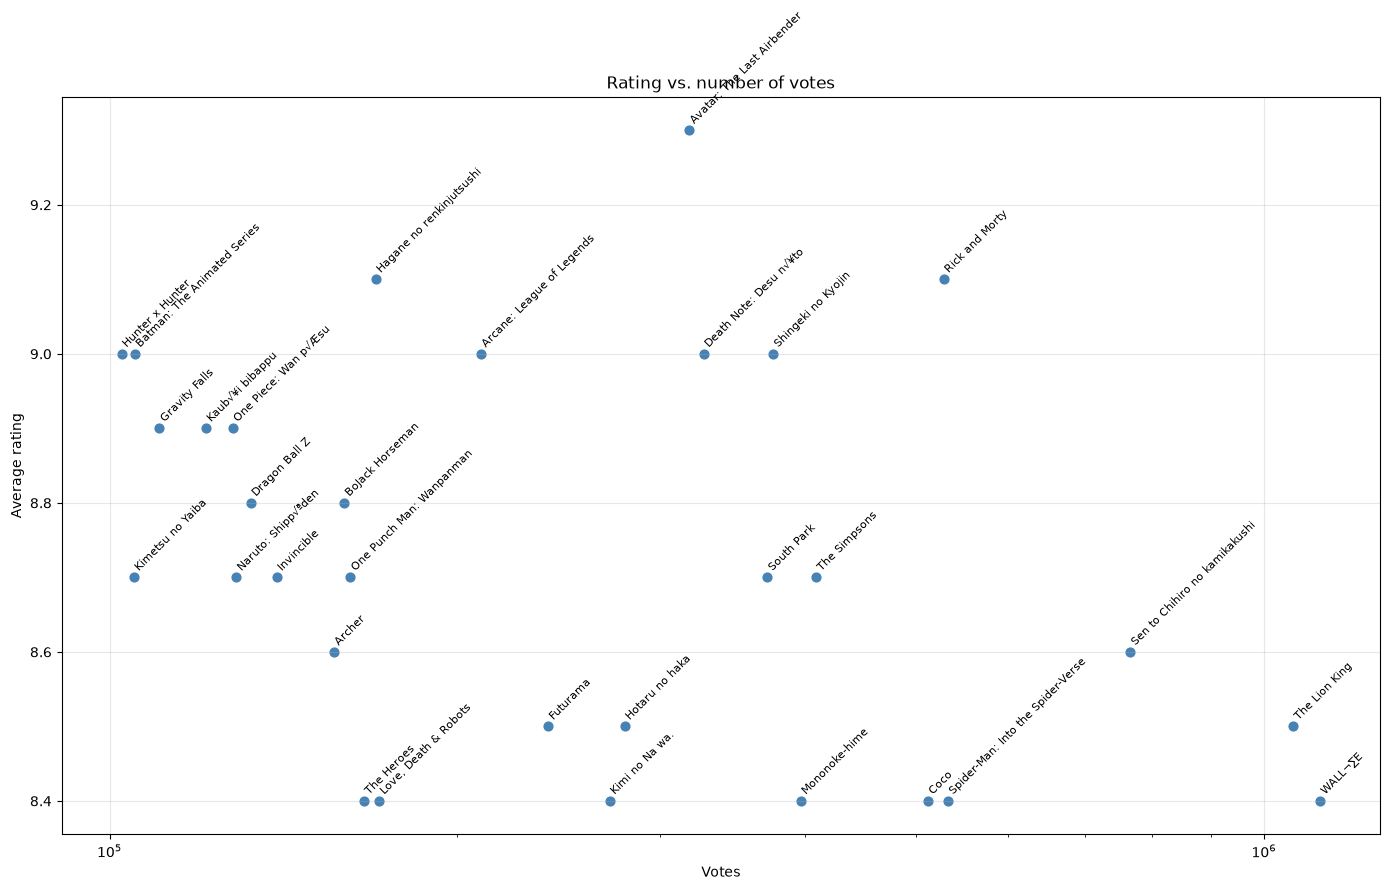

In [416]:
# now, let's visualize this in one big scatterplot

fig, ax = plt.subplots(figsize=(14, 9))

ax.scatter(selected_df['votes'], selected_df['rating'], s=40, color='steelblue')

for _, row in selected_df.iterrows():
    ax.annotate(
        row['title'],
        (row['votes'], row['rating']),
        xytext=(5, 3),
        textcoords='offset points',
        fontsize=8,
        rotation=45,
        rotation_mode='anchor',
        ha='left',
        va='bottom'
    )

ax.set_xlabel('Votes')
ax.set_ylabel('Average rating')
ax.set_title('Rating vs. number of votes')
ax.ticklabel_format(style='plain', axis='x')   # show 1,000,000 instead of 1e6
ax.grid(alpha=0.3)

plt.tight_layout()
ax.set_xscale('log')
plt.show()

In [417]:
#to make things easier i want to see a table with all three rating calculations as separate columns

high_votes_all_df = high_votes_df

C = high_votes_all_df['rating'].mean()
m1 = high_votes_all_df['votes'].quantile(0.05)  # PRIORITIZE RATING
m2 = high_votes_all_df['votes'].quantile(0.5)  # AVG
m3 = high_votes_all_df['votes'].quantile(0.95)  # PRIORITIZE VOTES

def weighted_rating1(row):
    v = row['votes']
    R = row['rating']
    return (v / (v + m1)) * R + (m1 / (v + m1)) * C

def weighted_rating2(row):
    v = row['votes']
    R = row['rating']
    return (v / (v + m2)) * R + (m2 / (v + m2)) * C

def weighted_rating3(row):
    v = row['votes']
    R = row['rating']
    return (v / (v + m3)) * R + (m3 / (v + m3)) * C

high_votes_all_df['weighted_rating_by_rating'] = high_votes_all_df.apply(weighted_rating1, axis=1)
high_votes_all_df['weighted_rating_avg'] = high_votes_all_df.apply(weighted_rating2, axis=1)
high_votes_all_df['weighted_rating_by_vote'] = high_votes_all_df.apply(weighted_rating3, axis=1)

best_shows_master_df = high_votes_df.sort_values(by='weighted_rating_avg', ascending=False)
best_shows_master_df = best_shows_master_df[['title', 'rating', 'votes', 'weighted_rating_by_rating','weighted_rating_avg', 'weighted_rating_by_vote']].head(50) # head(50) = output the top 50 shows
best_shows_master_df

,title,rating,votes,weighted_rating_by_rating,weighted_rating_avg,weighted_rating_by_vote
1385,Avatar: The Last Airbender,9.3,317686,9.231337,9.109073,8.209675
15160,Rick and Morty,9.1,527839,9.062197,8.992296,8.348862
16283,Shingeki no Kyojin,9.0,375741,8.950173,8.860156,8.142495
4165,Death Note: Desu n√¥to,9.0,327085,8.943002,8.841238,8.081766
7299,Hagane no renkinjutsushi,9.1,170030,8.987477,8.802092,7.841734
1133,Arcane: League of Legends,9.0,209650,8.912665,8.764269,7.892450
19574,The Simpsons,8.7,409471,8.662015,8.592937,8.020431
1760,Batman: The Animated Series,9.0,105198,8.834156,8.585557,7.643739
16817,South Park,8.7,371408,8.658234,8.582850,7.985063
8129,Hunter x Hunter,9.0,102420,8.830094,8.577028,7.635590


In [418]:
my_titles = [
    'Arcane: League of Legends',
    'Archer',
    'Avatar: The Last Airbender',
    'Batman: The Animated Series',
    'BoJack Horseman',
    'Coco',
    'Death Note: Desu n√¥to',
    'Dragon Ball Z',
    'Futurama',
    'Gravity Falls',
    'Hagane no renkinjutsushi',
    'Hotaru no haka',
    'Hunter x Hunter',
    'Invincible',
    'Kaub√¥i bibappu',
    'Kimetsu no Yaiba',
    'Kimi no Na wa.',
    'Love, Death & Robots',
    'Mononoke-hime',
    'Naruto: Shipp√ªden',
    'One Piece: Wan p√Æsu',
    'One Punch Man: Wanpanman',
    'Rick and Morty',
    'Sen to Chihiro no kamikakushi',
    'Shingeki no Kyojin',
    'South Park',
    'Spider-Man: Into the Spider-Verse',
    'The Heroes',
    'The Lion King',
    'The Simpsons',
    'WALL¬∑E'
]

best_shows_master_df = best_shows_master_df[best_shows_master_df['title'].isin(my_titles)]
best_shows_master_df

,title,rating,votes,weighted_rating_by_rating,weighted_rating_avg,weighted_rating_by_vote
1385,Avatar: The Last Airbender,9.3,317686,9.231337,9.109073,8.209675
15160,Rick and Morty,9.1,527839,9.062197,8.992296,8.348862
16283,Shingeki no Kyojin,9.0,375741,8.950173,8.860156,8.142495
4165,Death Note: Desu n√¥to,9.0,327085,8.943002,8.841238,8.081766
7299,Hagane no renkinjutsushi,9.1,170030,8.987477,8.802092,7.841734
1133,Arcane: League of Legends,9.0,209650,8.912665,8.764269,7.892450
19574,The Simpsons,8.7,409471,8.662015,8.592937,8.020431
1760,Batman: The Animated Series,9.0,105198,8.834156,8.585557,7.643739
16817,South Park,8.7,371408,8.658234,8.582850,7.985063
8129,Hunter x Hunter,9.0,102420,8.830094,8.577028,7.635590


In [419]:
print(len(best_shows_master_df))

32


In [420]:
#remove duplicates that have less votes
best_shows_master_df = (
    best_shows_master_df
    .sort_values(by='votes', ascending=False)
    .drop_duplicates(subset='title', keep='first')
)
best_shows_master_df

,title,rating,votes,weighted_rating_by_rating,weighted_rating_avg,weighted_rating_by_vote
21385,WALL¬∑E,8.4,1118407,8.388779,8.367373,8.119358
19002,The Lion King,8.5,1060542,8.487147,8.462665,8.182586
15998,Sen to Chihiro no kamikakushi,8.6,765949,8.580858,8.544812,8.167565
16931,Spider-Man: Into the Spider-Verse,8.4,532560,8.376685,8.333551,7.935142
15160,Rick and Morty,9.1,527839,9.062197,8.992296,8.348862
3559,Coco,8.4,511468,8.375744,8.330974,7.923891
19574,The Simpsons,8.7,409471,8.662015,8.592937,8.020431
12240,Mononoke-hime,8.4,396989,8.368937,8.312579,7.851884
16283,Shingeki no Kyojin,9.0,375741,8.950173,8.860156,8.142495
16817,South Park,8.7,371408,8.658234,8.582850,7.985063


In [421]:
#make sure that this new list is only the 31 overlaps
print(len(best_shows_master_df))

31


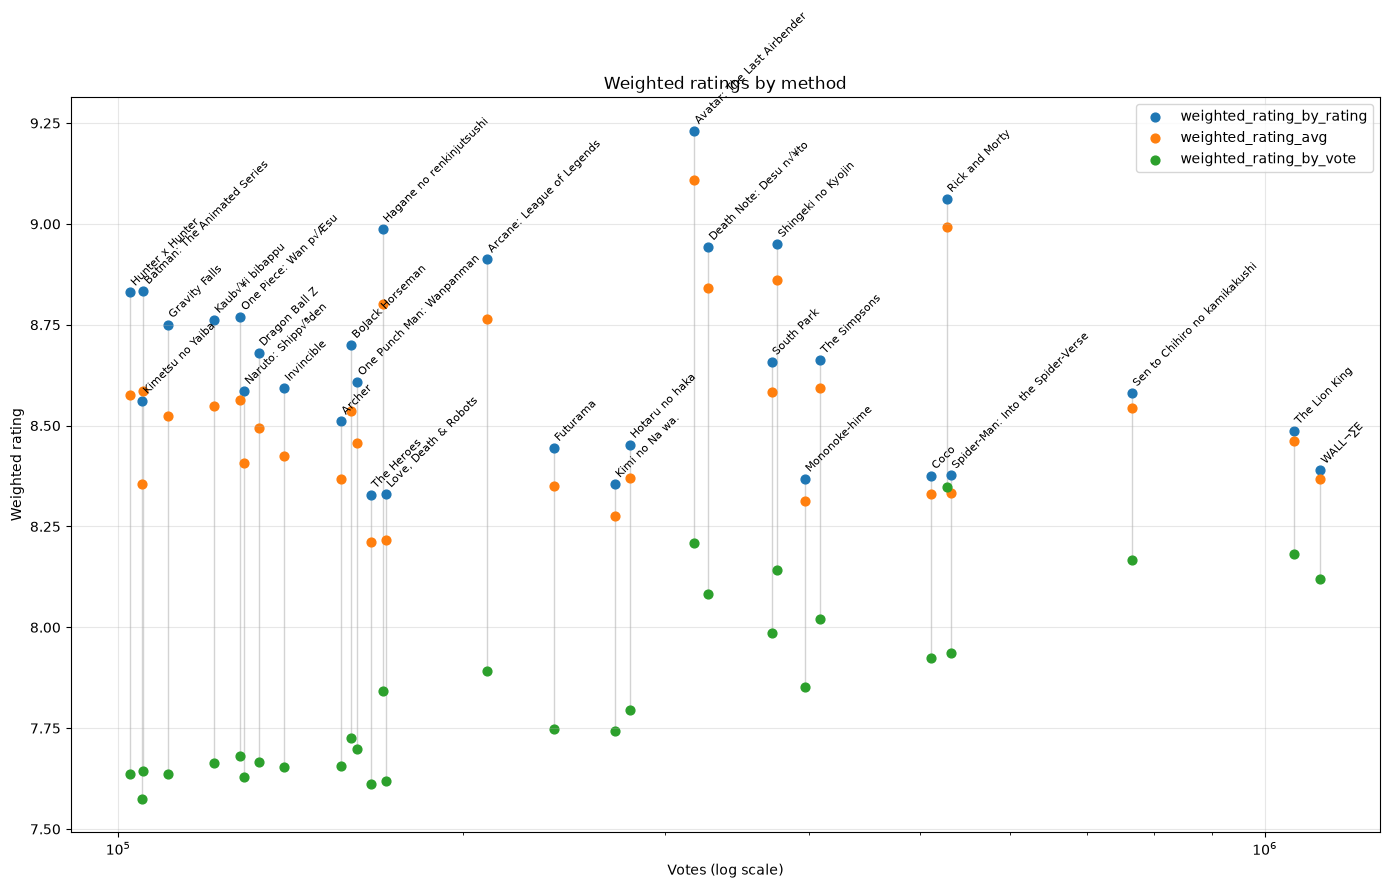

In [422]:
#i now want to show a plot of all three of these weighted averages in case it affects anything or gives any new insights.

fig, ax = plt.subplots(figsize=(14, 9))

rating_cols = {
    'weighted_rating_by_rating': 'tab:blue',
    'weighted_rating_avg':       'tab:orange',
    'weighted_rating_by_vote':   'tab:green',
}

# thin vertical line connecting each show's three dots
ax.vlines(
    best_shows_master_df['votes'],
    best_shows_master_df[list(rating_cols)].min(axis=1),
    best_shows_master_df[list(rating_cols)].max(axis=1),
    color='lightgray', linewidth=1, zorder=0
)

for col, color in rating_cols.items():
    ax.scatter(best_shows_master_df['votes'], best_shows_master_df[col],
               s=40, color=color, label=col)

# label each show once, next to its highest dot
for _, row in best_shows_master_df.iterrows():
    top = max(row[col] for col in rating_cols)
    ax.annotate(
        row['title'],
        (row['votes'], top),
        xytext=(5, 3),
        textcoords='offset points',
        fontsize=8,
        rotation=45,
        rotation_mode='anchor',
        ha='left',
        va='bottom'
    )

ax.set_xscale('log')
ax.set_xlabel('Votes (log scale)')
ax.set_ylabel('Weighted rating')
ax.set_title('Weighted ratings by method')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [423]:
# now, let's visualize this in one big scatterplot

best_shows_master_df = best_shows_master_df.sort_values(by='weighted_rating_by_rating',ascending=False) 

best_shows_master_df = best_shows_master_df[0:15]
best_shows_master_df

top15_by_rating_df = best_shows_master_df


In [424]:
#finally, here's a list of the top 15 animated shows with a rating that more accurately represents their popularity. based on this, our team can then investigate the animation styles used 
#and use these ratings as a rough proxy for how much their animation styles resonate with our audience
best_shows_master_df['final_avg_rating'] = best_shows_master_df[['weighted_rating_by_rating','weighted_rating_avg','weighted_rating_by_vote']].mean(axis=1).round(2)
best_shows_master_df = best_shows_master_df[['title', 'final_avg_rating']]
best_shows_master_df = best_shows_master_df.sort_values(by='final_avg_rating',ascending=False) 
best_shows_master_df

,title,final_avg_rating
1385,Avatar: The Last Airbender,8.85
15160,Rick and Morty,8.80
16283,Shingeki no Kyojin,8.65
4165,Death Note: Desu n√¥to,8.62
7299,Hagane no renkinjutsushi,8.54
1133,Arcane: League of Legends,8.52
19574,The Simpsons,8.43
16817,South Park,8.41
1760,Batman: The Animated Series,8.35
8129,Hunter x Hunter,8.35
